<a href="https://colab.research.google.com/github/HimanshiChoubal/Major_Project/blob/master/Updated_qcnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.2/56.2 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 28.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 43.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 27.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 37.2 MB/s eta 0:00:00
Using Colab cache for faster access to the 'deepglobe-road-extraction-dataset' dataset.


100%|██████████| 2.74G/2.74G [00:26<00:00, 110MB/s] 

Extracting files...


gdown failed: Failed to retrieve file url:

	Cannot retrieve the public link of the file. You may need to change
	
Mounted at /content/drive
using zip from Drive: /content/drive/MyDrive/data_original_size_v1.zip
roads: 6226 | urban: 803 | ttpla: 1242
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 112MB/s]


...

,task,QCNN 8q,LogReg (8 feat),MLP (8 feat),LogReg (512 feat),QCNN params,MLP params,acc on confident 80%
0,roads,0.652±0.022,0.662±0.029,0.684±0.024,0.710±0.018,21,161,0.688
1,urban,0.807±0.017,0.889±0.041,0.886±0.033,0.912±0.025,21,161,0.865
2,wires,0.847±0.047,0.878±0.039,0.885±0.029,0.860±0.028,21,161,0.898


##### ABLATION: 4 vs 8 qubits


,task,QCNN 4 qubits,QCNN 8 qubits
0,roads,0.613±0.026,0.652±0.022
1,urban,0.800±0.029,0.807±0.017
2,wires,0.841±0.037,0.847±0.047


##### NOISE: accuracy vs depolarizing noise


,task,noise 0.0,noise 0.01,noise 0.03,noise 0.05
0,roads,0.625,0.625,0.600,0.575
1,urban,0.825,0.825,0.800,0.800
2,wires,0.875,0.875,0.875,0.875


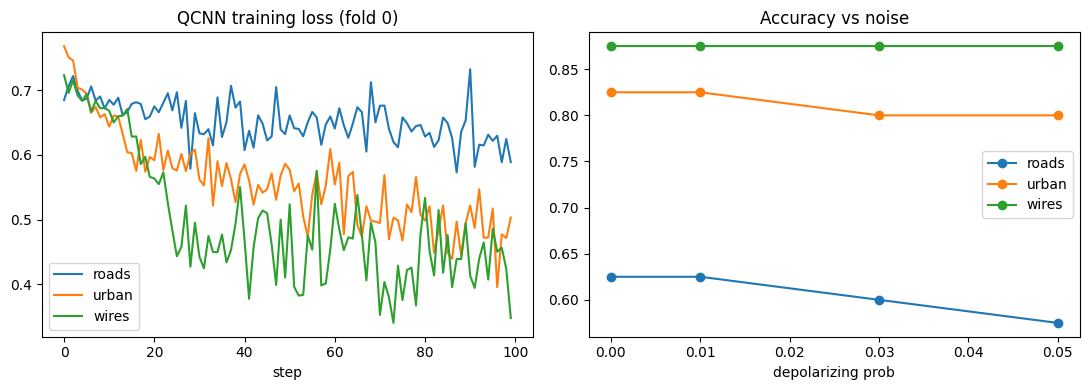

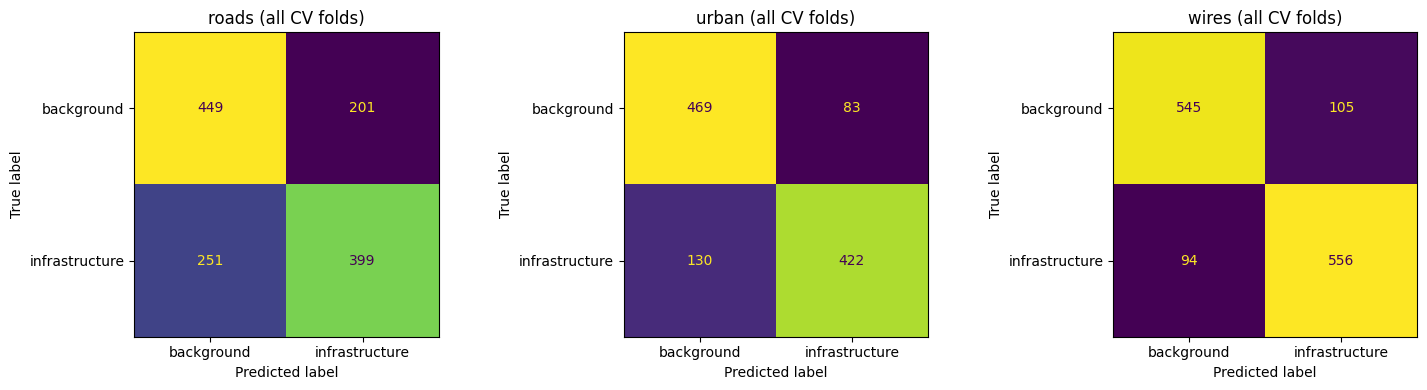

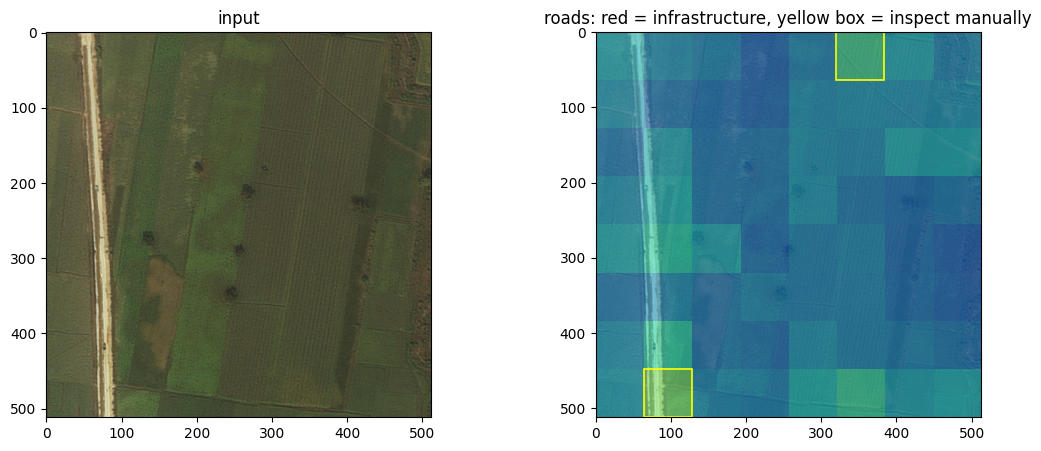

patches: 64 | predicted infrastructure: 0 | flagged for manual check: 2


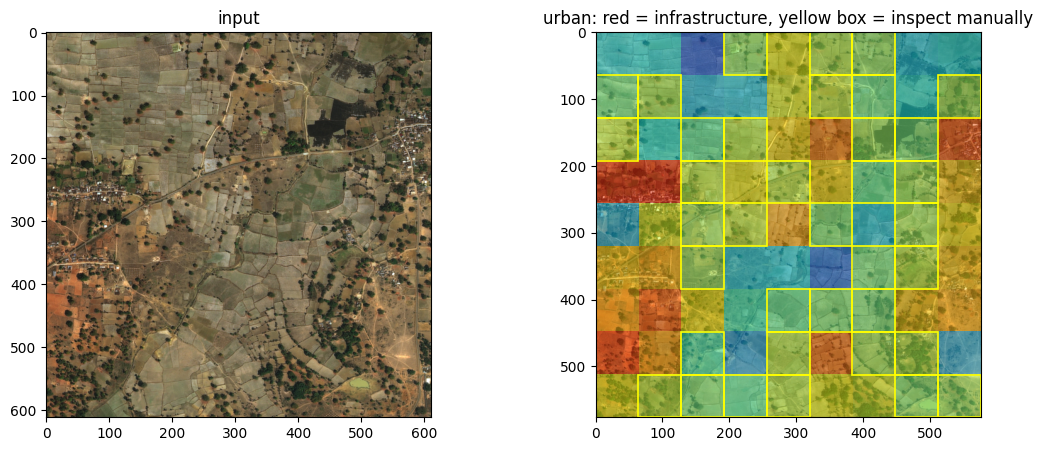

patches: 81 | predicted infrastructure: 51 | flagged for manual check: 37


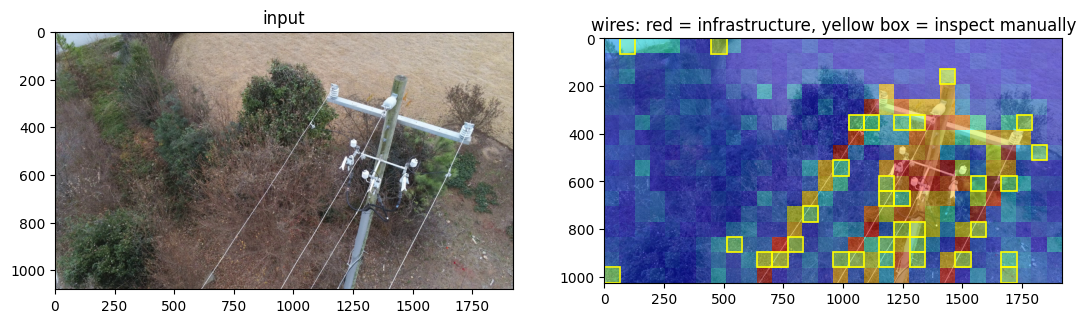

patches: 480 | predicted infrastructure: 88 | flagged for manual check: 33


In [ ]:
!pip install pennylane kagglehub gdown -q

import kagglehub, gdown, glob, os, zipfile, json
import numpy as np
from PIL import Image, ImageDraw

FOLDS, STEPS = 5, 100          # quick test: FOLDS, STEPS = 3, 40
N_PER_CLASS, PER_IMG, PATCH = 650, 6, 64      # 1300 patches per task

# ============ 1. DOWNLOAD DATA ============
road = kagglehub.dataset_download("balraj98/deepglobe-road-extraction-dataset")
land = kagglehub.dataset_download("balraj98/deepglobe-land-cover-classification-dataset")

ZIP = "ttpla_subset.zip"
def ok(p): return os.path.exists(p) and zipfile.is_zipfile(p)
if not ok(ZIP):
    try: gdown.download(id="1VHtu_ndp3arjMpyeAMtegSCux_21Qp7N", output=ZIP, quiet=False)
    except Exception as e: print("gdown failed:", str(e)[:100])
if not ok(ZIP):
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        for c in glob.glob("/content/drive/MyDrive/*.zip") + glob.glob("/content/drive/MyDrive/*/*.zip"):
            try:
                with zipfile.ZipFile(c) as z: names = z.namelist()
                if any(n.lower().endswith(".json") for n in names) and any(n.lower().endswith(".jpg") for n in names):
                    print("using zip from Drive:", c); ZIP = c; break
            except Exception: pass
    except Exception as e: print("Drive step failed:", str(e)[:100])
os.makedirs("/content/ttpla", exist_ok=True)
if ok(ZIP):
    with zipfile.ZipFile(ZIP) as z: z.extractall("/content/ttpla")
else:
    print("!! TTPLA zip not available -> wires task skipped")

road_files = [f for f in sorted(glob.glob(f"{road}/**/*_sat.jpg", recursive=True))
              if os.path.exists(f.replace("_sat.jpg", "_mask.png"))]
land_files = [f for f in sorted(glob.glob(f"{land}/**/*_sat.jpg", recursive=True))
              if os.path.exists(f.replace("_sat.jpg", "_mask.png"))]
tt_files = [f for f in sorted(glob.glob("/content/ttpla/**/*", recursive=True))
            if f.lower().endswith((".jpg", ".jpeg")) and os.path.exists(os.path.splitext(f)[0] + ".json")]
print("roads:", len(road_files), "| urban:", len(land_files), "| ttpla:", len(tt_files))

# ============ 2. LOADERS (RGB now) ============
def load_road(sat):
    g = Image.open(sat).convert("RGB").resize((512, 512))
    m = Image.open(sat.replace("_sat.jpg", "_mask.png")).convert("L").resize((512, 512), Image.NEAREST)
    return np.array(g), np.array(m) > 127

def load_urban(sat):                     # urban = cyan (0,255,255)
    g = Image.open(sat).convert("RGB").resize((612, 612))
    m = np.array(Image.open(sat.replace("_sat.jpg", "_mask.png")).convert("RGB").resize((612, 612), Image.NEAREST))
    return np.array(g), (m[..., 0] < 128) & (m[..., 1] > 128) & (m[..., 2] > 128)

def load_ttpla(jpg, scale=2):
    meta = json.load(open(os.path.splitext(jpg)[0] + ".json"))
    img = Image.open(jpg).convert("RGB"); W, H = img.size
    img = img.resize((W // scale, H // scale))
    mk = Image.new("L", img.size, 0); d = ImageDraw.Draw(mk)
    for s in meta["shapes"]:
        if "cable" in s["label"].lower() and len(s["points"]) >= 3:
            d.polygon([(x / scale, y / scale) for x, y in s["points"]], fill=1)
    return np.array(img), np.array(mk) > 0

def load_rgb(path, task):                # for the demo (no mask)
    img = Image.open(path).convert("RGB")
    if task == "roads": return np.array(img.resize((512, 512)))
    if task == "urban": return np.array(img.resize((612, 612)))
    W, H = img.size; return np.array(img.resize((W // 2, H // 2)))

# ============ 3. PRETRAINED FEATURE EXTRACTOR (classical, frozen) ============
import torch, torchvision
dev_t = "cuda" if torch.cuda.is_available() else "cpu"
cnn = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
cnn.fc = torch.nn.Identity(); cnn = cnn.eval().to(dev_t)
MEAN = torch.tensor([0.485, 0.456, 0.406], device=dev_t).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=dev_t).view(1, 3, 1, 1)

def cnn_features(P, bs=128):             # P: (N,64,64,3) uint8 -> (N,512)
    out = []
    with torch.no_grad():
        for i in range(0, len(P), bs):
            x = torch.from_numpy(P[i:i+bs]).to(dev_t).permute(0, 3, 1, 2).float() / 255
            x = torch.nn.functional.interpolate(x, size=112, mode="bilinear", align_corners=False)
            out.append(cnn((x - MEAN) / STD).cpu().numpy())
    return np.concatenate(out)

# ============ 4. BUILD PATCH POOLS (labels from masks, grouped by image) ============
def collect(files, loader, patch, thr, per_img, rng):
    P, y, grp = [], [], []
    for gi, f in enumerate(files):
        g, m = loader(f); pos, neg = [], []
        for yy in range(0, g.shape[0] - patch + 1, patch):
            for xx in range(0, g.shape[1] - patch + 1, patch):
                frac = m[yy:yy+patch, xx:xx+patch].mean()
                if frac >= thr: pos.append((yy, xx))
                elif frac == 0: neg.append((yy, xx))
        for lab, lst in ((1, pos), (0, neg)):
            if not lst: continue
            for s in rng.choice(len(lst), min(per_img, len(lst)), replace=False):
                yy, xx = lst[s]
                P.append(g[yy:yy+patch, xx:xx+patch].copy()); y.append(lab); grp.append(gi)
    return np.array(P), np.array(y), np.array(grp)

CFG = {
  "roads": dict(files=road_files, nfiles=150, loader=load_road,  thr=0.05),
  "urban": dict(files=land_files, nfiles=300, loader=load_urban, thr=0.50),
  "wires": dict(files=tt_files,   nfiles=150, loader=load_ttpla, thr=0.02),
}
DATA = {}
for name, c in CFG.items():
    if len(c["files"]) < 10: print(f"[skip] {name}: not enough files"); continue
    rng = np.random.default_rng(0)
    fl = list(c["files"]); rng.shuffle(fl); fl = fl[:c["nfiles"]]
    print(f"building {name} patches from {len(fl)} images ...")
    P, y, grp = collect(fl, c["loader"], PATCH, c["thr"], PER_IMG, rng)
    n = min(N_PER_CLASS, (y == 1).sum(), (y == 0).sum())
    if n < 50: print(f"[skip] {name}: too few patches of one class"); continue
    idx = np.concatenate([rng.choice(np.where(y == 1)[0], n, replace=False),
                          rng.choice(np.where(y == 0)[0], n, replace=False)])
    idx = rng.permutation(idx)
    F512 = cnn_features(P[idx])
    DATA[name] = (F512, y[idx], grp[idx])
    print(f"{name}: {len(idx)} patches ({n} per class), features {F512.shape}, images used {len(set(grp[idx]))}")

# ============ 5. QCNN (any qubit count, optional noise) ============
import pennylane as qml

def conv(p, a, b):
    qml.RY(p[0], wires=a); qml.RY(p[1], wires=b)
    qml.CNOT(wires=[a, b]); qml.RZ(p[2], wires=b); qml.CNOT(wires=[b, a])
    qml.RY(p[3], wires=a); qml.RY(p[4], wires=b)

def pool(p, a, b):                        # a discarded, b kept
    qml.CRZ(p[0], wires=[a, b]); qml.PauliX(wires=a); qml.CRX(p[1], wires=[a, b])

_cache = {}
def get_qnode(n, noise=0.0):
    key = (n, noise)
    if key in _cache: return _cache[key]
    dev = qml.device("default.mixed" if noise > 0 else "default.qubit", wires=n)
    def nz(ws):
        if noise > 0:
            for q in ws: qml.DepolarizingChannel(noise, wires=q)
    @qml.qnode(dev, interface="torch")
    def circuit(x, w, pw):
        qml.AngleEmbedding(x, wires=range(n), rotation="Y")       # angle encoding
        wires, l = list(range(n)), 0
        while len(wires) > 1:
            for i in range(0, len(wires) - 1, 2): conv(w[l], wires[i], wires[i+1]); nz([wires[i], wires[i+1]])
            for i in range(0, len(wires) - 1, 2): pool(pw[l], wires[i], wires[i+1]); nz([wires[i], wires[i+1]])
            wires = wires[1::2]; l += 1
        return qml.expval(qml.PauliZ(wires[0]))
    _cache[key] = circuit; return circuit

def predict_prob(circ, X, w, pw):
    with torch.no_grad():
        return ((circ(X, w, pw) + 1) / 2).numpy()

def train_qcnn(n, Xtr, ytr, Xte, steps=STEPS, bs=64, lr=0.05, seed=0):
    torch.manual_seed(seed); L = int(np.log2(n)); circ = get_qnode(n)
    w  = (0.5 * torch.randn(L, 5, dtype=torch.float64)).requires_grad_()
    pw = (0.5 * torch.randn(L, 2, dtype=torch.float64)).requires_grad_()
    opt = torch.optim.Adam([w, pw], lr=lr)
    Xt = torch.tensor(Xtr, dtype=torch.float64); yt = torch.tensor(ytr, dtype=torch.float64)
    hist = []
    for s in range(steps):
        idx = torch.randperm(len(Xt))[:bs]
        prob = ((circ(Xt[idx], w, pw) + 1) / 2).clamp(1e-5, 1 - 1e-5)
        loss = torch.nn.functional.binary_cross_entropy(prob, yt[idx])
        opt.zero_grad(); loss.backward(); opt.step(); hist.append(loss.item())
    w, pw = w.detach(), pw.detach()
    pte = predict_prob(circ, torch.tensor(Xte, dtype=torch.float64), w, pw)
    return pte, w, pw, hist, w.numel() + pw.numel()

def eval_noisy(n, Xte, yte, w, pw, p, m=40):
    circ = get_qnode(n, p); m = min(m, len(Xte)); probs = []
    with torch.no_grad():
        for i in range(m):
            probs.append(((circ(torch.tensor(Xte[i], dtype=torch.float64), w, pw) + 1) / 2).item())
    return ((np.array(probs) > 0.5) == yte[:m]).mean()

# ============ 6. 5-FOLD CROSS-VALIDATION (split by image) ============
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def prep(k, Xtr, Xte):
    pca = PCA(k).fit(Xtr)                                        # fit on TRAIN fold only
    sc = MinMaxScaler((0, np.pi)).fit(pca.transform(Xtr))
    f = lambda X: np.clip(sc.transform(pca.transform(X)), 0, np.pi)
    return pca, sc, f(Xtr), f(Xte)

ms = lambda a: f"{np.mean(a):.3f}±{np.std(a):.3f}"
MODELS, main_rows, abl_rows, noise_rows, curves, cms = {}, [], [], [], {}, {}
NOISE = [0.0, 0.01, 0.03, 0.05]

for name, (F512, y, grp) in DATA.items():
    print(f"\n=== {name} ===")
    oof = np.zeros(len(y)); a8, a4, alr, amlp, a512 = [], [], [], [], []
    for fold, (tr, te) in enumerate(GroupKFold(FOLDS).split(F512, y, grp)):
        pca, sc, Ftr, Fte = prep(8, F512[tr], F512[te])
        pte, w, pw, hist, npar = train_qcnn(8, Ftr, y[tr], Fte, seed=fold)
        oof[te] = pte; a8.append(((pte > 0.5) == y[te]).mean())

        alr.append(LogisticRegression(max_iter=1000).fit(Ftr, y[tr]).score(Fte, y[te]))
        amlp.append(MLPClassifier((16,), max_iter=2000, random_state=0).fit(Ftr, y[tr]).score(Fte, y[te]))
        a512.append(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
                    .fit(F512[tr], y[tr]).score(F512[te], y[te]))

        _, _, Ftr4, Fte4 = prep(4, F512[tr], F512[te])           # 4-qubit ablation
        pte4, *_ = train_qcnn(4, Ftr4, y[tr], Fte4, seed=fold)
        a4.append(((pte4 > 0.5) == y[te]).mean())
        print(f"  fold {fold}: QCNN8 {a8[-1]:.3f} | QCNN4 {a4[-1]:.3f} | LogReg8 {alr[-1]:.3f} | LogReg512 {a512[-1]:.3f}")

        if fold == 0:                                             # keep fold-0 model for noise test + demo
            curves[name] = hist
            MODELS[name] = dict(pca=pca, sc=sc, w=w, pw=pw)
            row = {"task": name}
            for p in NOISE: row[f"noise {p}"] = round(eval_noisy(8, Fte, y[te], w, pw, p), 3)
            noise_rows.append(row); print("  noise:", row)

    cms[name] = confusion_matrix(y, (oof > 0.5).astype(int))
    conf = np.abs(oof - 0.5); flag = conf <= np.quantile(conf, 0.20)    # 20% least-confident -> manual check
    conf_acc = ((oof[~flag] > 0.5) == y[~flag]).mean()
    main_rows.append({"task": name, "QCNN 8q": ms(a8), "LogReg (8 feat)": ms(alr), "MLP (8 feat)": ms(amlp),
                      "LogReg (512 feat)": ms(a512), "QCNN params": npar, "MLP params": 161,
                      "acc on confident 80%": round(conf_acc, 3)})
    abl_rows.append({"task": name, "QCNN 4 qubits": ms(a4), "QCNN 8 qubits": ms(a8)})

print("\n##### MAIN RESULTS (5-fold CV, mean±std)");  display(pd.DataFrame(main_rows))
print("##### ABLATION: 4 vs 8 qubits");               display(pd.DataFrame(abl_rows))
print("##### NOISE: accuracy vs depolarizing noise");  display(pd.DataFrame(noise_rows))
pd.DataFrame(main_rows).to_csv("results_main.csv", index=False)
pd.DataFrame(abl_rows).to_csv("results_ablation.csv", index=False)
pd.DataFrame(noise_rows).to_csv("results_noise.csv", index=False)

# ---- plots ----
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k, h in curves.items(): ax[0].plot(h, label=k)
ax[0].set_title("QCNN training loss (fold 0)"); ax[0].set_xlabel("step"); ax[0].legend()
for r in noise_rows: ax[1].plot(NOISE, [r[f"noise {p}"] for p in NOISE], marker="o", label=r["task"])
ax[1].set_title("Accuracy vs noise"); ax[1].set_xlabel("depolarizing prob"); ax[1].legend()
plt.tight_layout(); plt.savefig("loss_noise.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, len(cms), figsize=(5 * len(cms), 4)); ax = np.atleast_1d(ax)
for a, (k, cm) in zip(ax, cms.items()):
    ConfusionMatrixDisplay(cm, display_labels=["background", "infrastructure"]).plot(ax=a, colorbar=False)
    a.set_title(f"{k} (all CV folds)")
plt.tight_layout(); plt.savefig("confusion.png", dpi=150); plt.show()

# ============ 7. DEMO: prediction map with confidence ============
def demo(path, task, band=0.1):
    M = MODELS[task]; g = load_rgb(path, task); P = PATCH
    ys = list(range(0, g.shape[0] - P + 1, P)); xs = list(range(0, g.shape[1] - P + 1, P))
    patches = np.array([g[y:y+P, x:x+P] for y in ys for x in xs])
    F = np.clip(M["sc"].transform(M["pca"].transform(cnn_features(patches))), 0, np.pi)
    p = predict_prob(get_qnode(8), torch.tensor(F, dtype=torch.float64), M["w"], M["pw"])
    grid = p.reshape(len(ys), len(xs)); unsure = np.abs(grid - 0.5) < band
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    ax[0].imshow(g); ax[0].set_title("input")
    ax[1].imshow(g)
    ax[1].imshow(grid, extent=(0, len(xs)*P, len(ys)*P, 0), alpha=0.45, cmap="jet", vmin=0, vmax=1, interpolation="nearest")
    for i, j in zip(*np.where(unsure)):
        ax[1].add_patch(plt.Rectangle((j*P, i*P), P, P, fill=False, edgecolor="yellow", lw=1.2))
    ax[1].set_title(f"{task}: red = infrastructure, yellow box = inspect manually")
    plt.show()
    print(f"patches: {grid.size} | predicted infrastructure: {(grid > 0.5).sum()} | flagged for manual check: {unsure.sum()}")

if "roads" in MODELS: demo(road_files[300], "roads")
if "urban" in MODELS: demo(land_files[500], "urban")
if "wires" in MODELS and len(tt_files) > 7: demo(tt_files[7], "wires")